In [1]:
import pandas as pd 
import numpy as np

import matplotlib.pyplot as plt
plt.rcParams['figure.figsize']=(14.4,7.4)

In [2]:
# reading the oslo data for 300 bin (6,9)

df=pd.read_csv("gsf_97Zr.csv")

# convert to python arrays
energy1=df["energy"].values # as numpy array
gsf1=df["gsf"].values 
error1=df["errors"].values

In [3]:
df2=pd.read_csv("gsf_100Zr_baseline_full.csv")

# convert to python arrays
energy2=df2["energy"].values # as numpy array
gsf2=df2["gsf"].values 
error2=df2["errors"].values


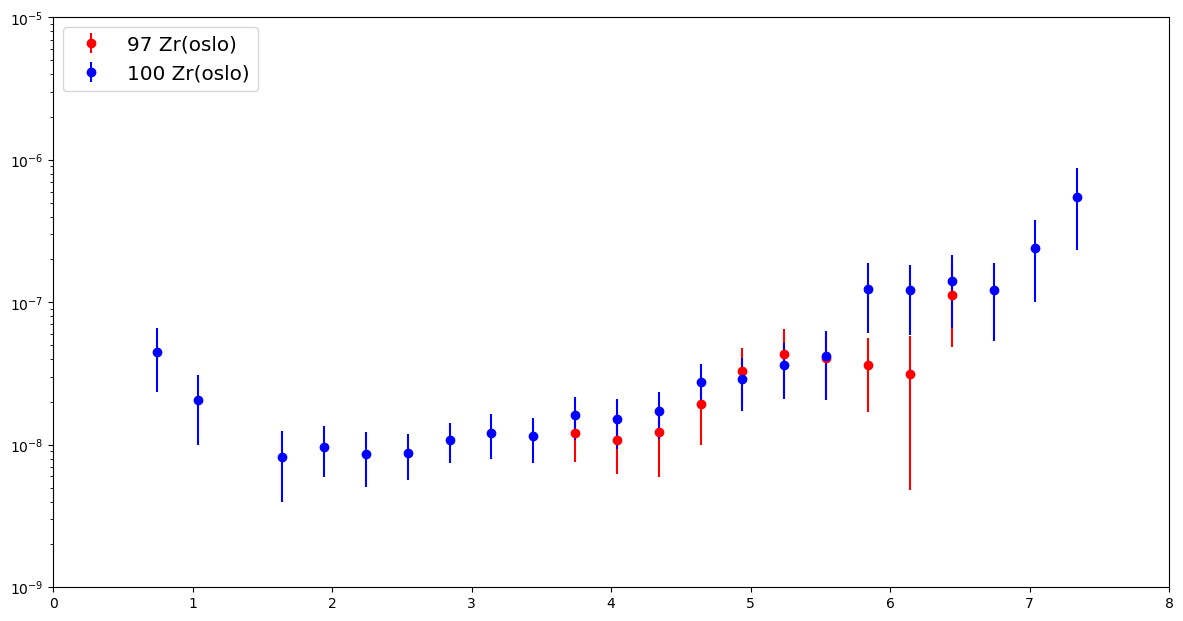

array([4.4758906e-08, 2.0577430e-08, 8.2366070e-09, 9.6836175e-09,
       8.6493381e-09, 8.7664631e-09, 1.0845674e-08, 1.2133087e-08,
       1.1474363e-08, 1.6201378e-08, 1.5081566e-08, 1.7300186e-08,
       2.7548554e-08, 2.9123802e-08, 3.6550414e-08, 4.1996614e-08,
       1.2455135e-07, 1.2124178e-07, 1.4063339e-07, 1.2180678e-07,
       2.3900071e-07, 5.5274694e-07])

In [4]:

fig = plt.figure()

plt.errorbar(energy1, gsf1,yerr=error1,fmt="o", color="r",ecolor='r',label='97 Zr(oslo)')
plt.errorbar(energy2, gsf2,yerr=error2,fmt="o", color="b",ecolor='b',label='100 Zr(oslo)')


plt.yscale("log")

plt.xlim(0, 8)
plt.ylim(10**(-9),10**(-5))

plt.legend(loc ='upper left',fontsize="x-large")
plt.show()

gsf2

In [25]:
df3=pd.read_table("optimal_talys.txt",delimiter="\s+",skiprows=2,header=None)
# some shit i tried, i am tired
#df8=pd.read_table("C:\\Users\\amals\\Downloads\\randomgsf.txt",delimiter="\s+",skiprows=2,header=None)
df3.columns=['energy','f(M1)','f(E1)','T(M1)','T(E1)']
df3['gsf'] = df3['f(M1)'] + df3['f(E1)']



<>:1: SyntaxWarning: invalid escape sequence '\s'
<>:1: SyntaxWarning: invalid escape sequence '\s'
C:\Users\amals\AppData\Local\Temp\ipykernel_21680\3480197927.py:1: SyntaxWarning: invalid escape sequence '\s'
  df3=pd.read_table("optimal_talys.txt",delimiter="\s+",skiprows=2,header=None)


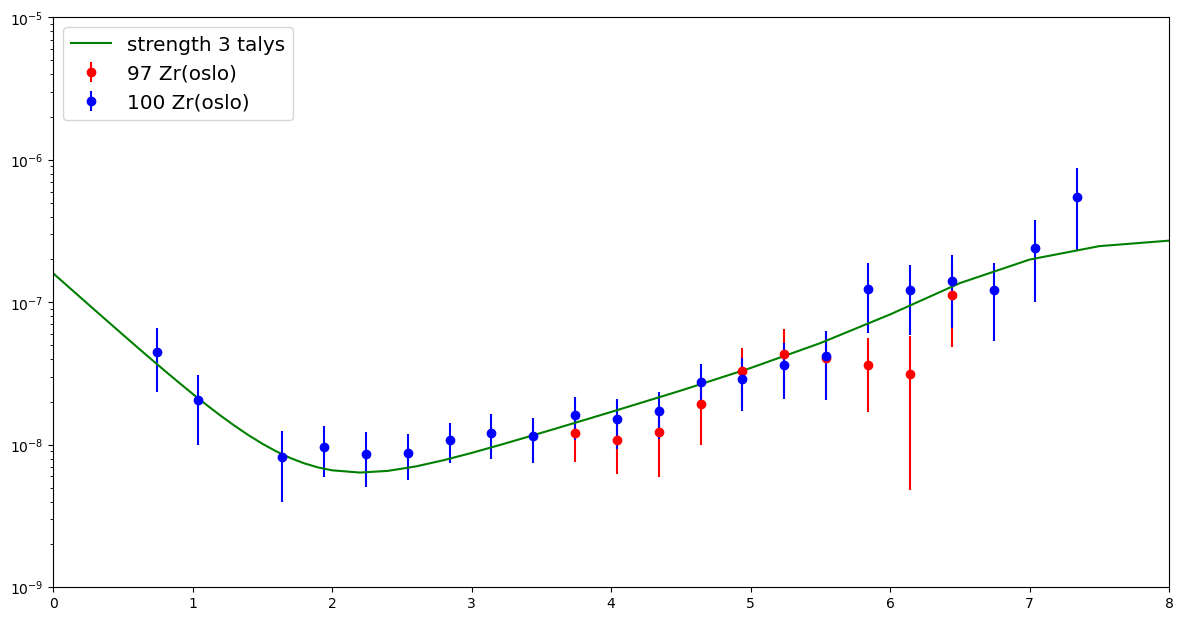

array([4.4758906e-08, 2.0577430e-08, 8.2366070e-09, 9.6836175e-09,
       8.6493381e-09, 8.7664631e-09, 1.0845674e-08, 1.2133087e-08,
       1.1474363e-08, 1.6201378e-08, 1.5081566e-08, 1.7300186e-08,
       2.7548554e-08, 2.9123802e-08, 3.6550414e-08, 4.1996614e-08,
       1.2455135e-07, 1.2124178e-07, 1.4063339e-07, 1.2180678e-07,
       2.3900071e-07, 5.5274694e-07])

In [27]:
fig = plt.figure()

plt.errorbar(energy1, gsf1,yerr=error1,fmt="o", color="r",ecolor='r',label='97 Zr(oslo)')
plt.errorbar(energy2, gsf2,yerr=error2,fmt="o", color="b",ecolor='b',label='100 Zr(oslo)')

plt.plot(df3['energy'],df3['gsf'],color ='green', label ='strength 3 talys')

plt.yscale("log")

plt.xlim(0, 8)
plt.ylim(10**(-9),10**(-5))

plt.legend(loc ='upper left',fontsize="x-large")
plt.show()

gsf2

In [33]:
df_construct=pd.read_table("base_strength.txt",delimiter="\s+",skiprows=2,header=None)
# some shit i tried, i am tired
#df8=pd.read_table("C:\\Users\\amals\\Downloads\\randomgsf.txt",delimiter="\s+",skiprows=2,header=None)
df_construct.columns=['energy','f(M1)','f(E1)','T(M1)','T(E1)']

df_construct['gsf'] = df_construct['f(E1)']+ df_construct['f(M1)']

df_construct.to_pickle("master_base_gsf.pkl")

# f(E1)
ftable=1
C= 0
U =  6.827386
eta =3

#f(M1)
upbende =2
upbendc = 1.6*10**(-7)

# f(e1) construction
df_construct['f(E1)']= ftable * df_construct['f(E1)']+  (C* (U-df_construct['energy']))/(1+np.exp(df_construct['energy']-eta))

#f(m1) construction
df_construct['f(M1)']=  df_construct['f(M1)']+  upbendc * np.exp(-1*upbende*df_construct['energy'])

df_construct['gsf'] = df_construct['f(E1)']+ df_construct['f(M1)']


df_construct.head(30)


<>:1: SyntaxWarning: invalid escape sequence '\s'
<>:1: SyntaxWarning: invalid escape sequence '\s'
C:\Users\amals\AppData\Local\Temp\ipykernel_21680\2208037539.py:1: SyntaxWarning: invalid escape sequence '\s'
  df_construct=pd.read_table("base_strength.txt",delimiter="\s+",skiprows=2,header=None)


,energy,f(M1),f(E1),T(M1),T(E1),gsf
0,0.001,1.596803e-07,0.000000e+00,0.000000e+00,0.000000e+00,1.596803e-07
1,0.002,1.593623e-07,0.000000e+00,5.279990e-20,0.000000e+00,1.593623e-07
2,0.005,1.584106e-07,0.000000e+00,2.062500e-18,0.000000e+00,1.584106e-07
3,0.010,1.568370e-07,0.000000e+00,3.300000e-17,0.000000e+00,1.568370e-07
4,0.020,1.537368e-07,0.000000e+00,5.280030e-16,0.000000e+00,1.537368e-07
5,0.050,1.448002e-07,0.000000e+00,2.062610e-14,0.000000e+00,1.448002e-07
6,0.100,1.310495e-07,0.000000e+00,3.300750e-13,0.000000e+00,1.310495e-07
7,0.200,1.073563e-07,2.328900e-11,5.284850e-12,1.170630e-12,1.073796e-07
8,0.300,8.796775e-08,5.246730e-11,2.678530e-11,8.900870e-12,8.802022e-08
9,0.400,7.210349e-08,9.341630e-11,8.479150e-11,3.756490e-11,7.219691e-08


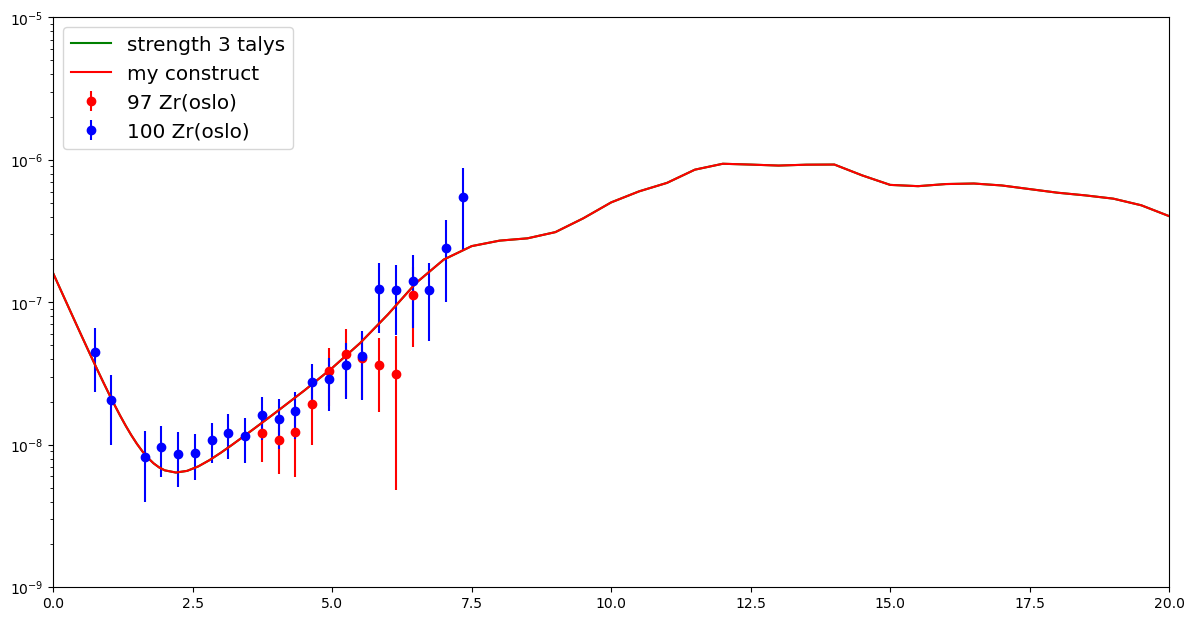

In [35]:
fig = plt.figure()

plt.errorbar(energy1, gsf1,yerr=error1,fmt="o", color="r",ecolor='r',label='97 Zr(oslo)')
plt.errorbar(energy2, gsf2,yerr=error2,fmt="o", color="b",ecolor='b',label='100 Zr(oslo)')

plt.plot(df3['energy'],df3['gsf'],color ='green', label ='strength 3 talys')

plt.plot(df_construct['energy'],df_construct['gsf'],color ='red', label ='my construct')

plt.yscale("log")

plt.xlim(0, 20)
plt.ylim(10**(-9),10**(-5))

plt.legend(loc ='upper left',fontsize="x-large")
plt.show()

